# Homework 7 problem 2 <br>
Filippa Mudsam

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

For the six rates above compute E[M] and the probability that each student
is last, by following the group of students still working. With a group still working, the next
finish takes a time with mean 1/(sum of their rates) and is by student i with probability
λi/(sum of their rates), after which the same problem continues with student i removed. Do
this for all 26 groups, starting from all six students.

In [11]:
rng = np.random.default_rng()

lam = np.array([3, 2, 1.5, 1.2, 1, 0.75])  
n = len(lam)

In [12]:
def follow_group(group):
    total = np.sum(lam[group])
    last = np.zeros(n)

    if len(group) == 1:         
        last[group[0]] = 1
        return 1/total, last

    EM = 1/total                
    for i in group:
        rest = [s for s in group if s != i]    
        EM_rest, last_rest = follow_group(rest)
        EM = EM + lam[i]/total*EM_rest
        last = last + lam[i]/total*last_rest
    return EM, last

EM_exact, last_exact = follow_group(list(range(n)))
print('E[M] =', EM_exact)
for i in range(n):
    print('P(student %d last) = %.4f' % (i + 1, last_exact[i]))

E[M] = 2.1073764063261615
P(student 1 last) = 0.0268
P(student 2 last) = 0.0695
P(student 3 last) = 0.1230
P(student 4 last) = 0.1813
P(student 5 last) = 0.2410
P(student 6 last) = 0.3585


Also compute E[M ] from the alternating
formula of (c).

In [13]:
def alternating(rates):
    EM = 0
    for size in range(1, len(rates) + 1):
        for group in combinations(rates, size):
            EM = EM + (-1)**(size + 1)/np.sum(group)
    return EM

print('E[M] (alternating formula) =', alternating(lam))

E[M] (alternating formula) = 2.107376406326162


Simulate 2 × 105 exams and compare, and plot a histogram of M against
the exact density d Q (1 − e−λit). Check by simulation that the finishing time of the first dt i
student does not depend on who that student is.

In [14]:
Nsim = int(2e5)
U = rng.random((Nsim, n))
X = -np.log(U)/lam           

M = np.max(X, axis=1)       
last_sim = np.argmax(X, axis=1)

print('E[M]:  exact =', EM_exact, '  simulated =', np.mean(M))
for i in range(n):
    print('P(student %d last):  exact = %.4f   simulated = %.4f'
          % (i + 1, last_exact[i], np.mean(last_sim == i)))

E[M]:  exact = 2.1073764063261615   simulated = 2.10182614989215
P(student 1 last):  exact = 0.0268   simulated = 0.0270
P(student 2 last):  exact = 0.0695   simulated = 0.0697
P(student 3 last):  exact = 0.1230   simulated = 0.1231
P(student 4 last):  exact = 0.1813   simulated = 0.1817
P(student 5 last):  exact = 0.2410   simulated = 0.2405
P(student 6 last):  exact = 0.3585   simulated = 0.3579


histogram

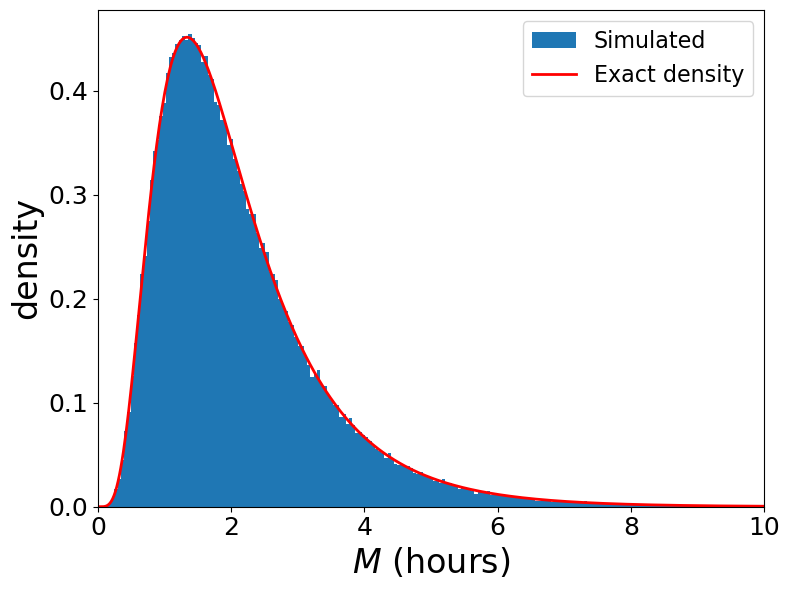

In [15]:
x = np.linspace(0, 10, 500)
f = np.zeros(len(x))
for i in range(n):
    term = lam[i]*np.exp(-lam[i]*x)
    for j in range(n):
        if j != i:
            term = term*(1 - np.exp(-lam[j]*x))
    f = f + term

plt.figure(1, figsize=(8, 6))
plt.hist(M, bins='fd', density=True, label='Simulated')
plt.plot(x, f, 'r-', linewidth=2, label='Exact density')
plt.xlim([0, 10])
plt.legend(fontsize=16)
plt.tick_params(labelsize=18)
plt.xlabel('$M$ (hours)', fontsize=24)
plt.ylabel('density', fontsize=24)
plt.tight_layout()
plt.show()

In [16]:
first_time = np.min(X, axis=1)
first_who = np.argmin(X, axis=1)

print('1/Lambda =', 1/np.sum(lam))
for i in range(n):
    print('student %d first:  mean first finishing time = %.4f'
          % (i + 1, np.mean(first_time[first_who == i])))

1/Lambda = 0.10582010582010583
student 1 first:  mean first finishing time = 0.1058
student 2 first:  mean first finishing time = 0.1052
student 3 first:  mean first finishing time = 0.1065
student 4 first:  mean first finishing time = 0.1069
student 5 first:  mean first finishing time = 0.1064
student 6 first:  mean first finishing time = 0.1084


Then take rates λi = i for k = 1,...,12 students and plot E[M] against k. Does it grow without bound?

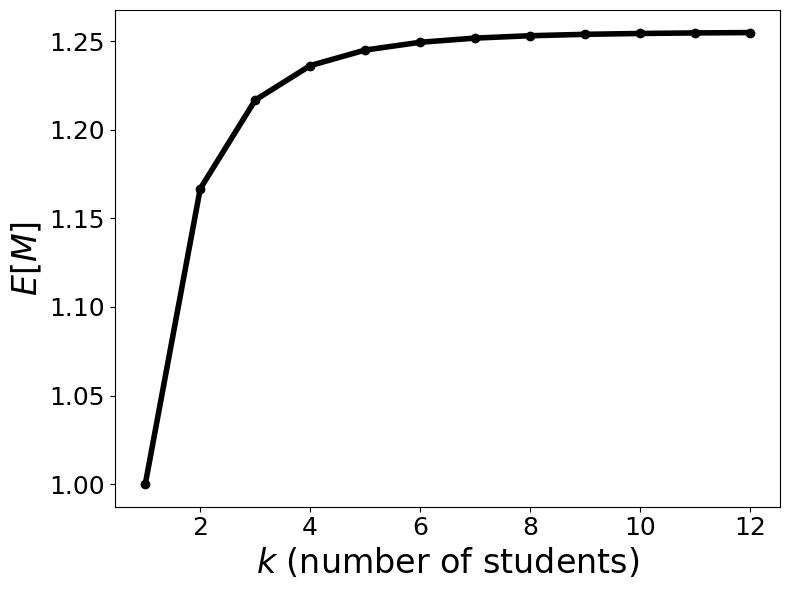

[1.         1.16666667 1.21666667 1.23611111 1.24490232 1.24929464
 1.25165255 1.25298922 1.25378027 1.25426505 1.25457091 1.2547687 ]


In [17]:
k_vals = np.arange(1, 13)
EM_k = np.zeros(len(k_vals))
for j in range(len(k_vals)):
    EM_k[j] = alternating(np.arange(1, k_vals[j] + 1))

plt.figure(2, figsize=(8, 6))
plt.plot(k_vals, EM_k, 'k-o', linewidth=4)
plt.tick_params(labelsize=18)
plt.xlabel('$k$ (number of students)', fontsize=24)
plt.ylabel('$E[M]$', fontsize=24)
plt.tight_layout()
plt.show()

print(EM_k)

It does not grow without a bound.